<a href="https://colab.research.google.com/github/tofighi/tutorials/blob/master/AI/Naive_Bayes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Naive Bayes Classification Tutorial using Scikit-learn
This notebook covers how to build and evaluate a Naive Bayes Classifier using Python's Scikit-learn package, featuring both a synthetic dataset and a real-world loan dataset.
Tutorial source: [DataCamp Naive Bayes Classifier Tutorial](https://www.datacamp.com/tutorial/naive-bayes-scikit-learn)

## 1. Naive Bayes Classifier with a Synthetic Dataset
We will generate a synthetic dataset using scikit-learn and train/evaluate the Gaussian Naive Bayes algorithm.

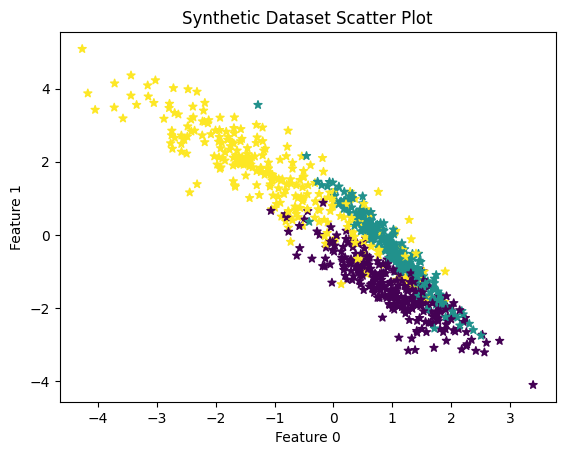

In [1]:
from sklearn.datasets import make_classification
import matplotlib.pyplot as plt

# Generate synthetic dataset with 6 features, 3 classes, and 800 samples
X, y = make_classification(
    n_features=6,
    n_classes=3,
    n_samples=800,
    n_informative=2,
    random_state=1,
    n_clusters_per_class=1,
)

# Visualize the dataset
plt.scatter(X[:, 0], X[:, 1], c=y, marker="*")
plt.xlabel("Feature 0")
plt.ylabel("Feature 1")
plt.title("Synthetic Dataset Scatter Plot")
plt.show()

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB

# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.33, random_state=125
)

# Build and train the Gaussian Naive Bayes model
model = GaussianNB()
model.fit(X_train, y_train)

# Predict a single sample
predicted = model.predict([X_test[6]])
print("Actual Value:", y_test[6])
print("Predicted Value:", predicted[0])

Actual Value: 0
Predicted Value: 0


Accuracy: 0.8484848484848485
F1 Score: 0.8491119695890328


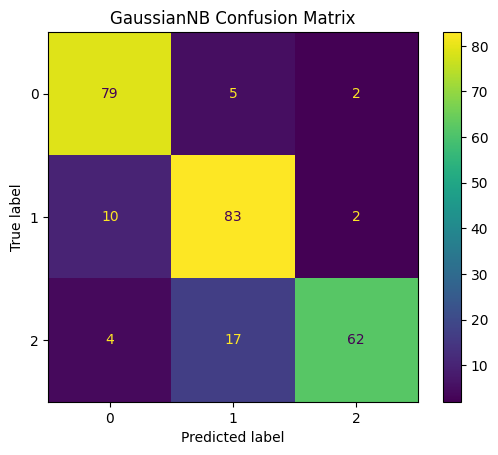

In [3]:
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
)

# Predict on test set
y_pred = model.predict(X_test)
accuracy = accuracy_score(y_pred, y_test)
f1 = f1_score(y_pred, y_test, average="weighted")

print("Accuracy:", accuracy)
print("F1 Score:", f1)

# Plot Confusion Matrix
labels = [0, 1, 2]
cm = confusion_matrix(y_test, y_pred, labels=labels)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
disp.plot()
plt.title("GaussianNB Confusion Matrix")
plt.show()

## 2. Naive Bayes Classifier with a Loan Dataset
Next, we train the Naive Bayes Classifier on a real-world loan dataset (`loan_data.csv`).

,index,credit.policy,purpose,int.rate,installment,log.annual.inc,dti,fico,days.with.cr.line,revol.bal,revol.util,inq.last.6mths,delinq.2yrs,pub.rec,not.fully.paid
0,0,1,debt_consolidation,0.1189,829.10,11.350407,19.48,737,5639.958333,28854,52.1,0,0,0,0
1,1,1,credit_card,0.1071,228.22,11.082143,14.29,707,2760.000000,33623,76.7,0,0,0,0
2,2,1,debt_consolidation,0.1357,366.86,10.373491,11.63,682,4710.000000,3511,25.6,1,0,0,0
3,3,1,debt_consolidation,0.1008,162.34,11.350407,8.10,712,2699.958333,33667,73.2,1,0,0,0
4,4,1,credit_card,0.1426,102.92,11.299732,14.97,667,4066.000000,4740,39.5,0,1,0,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   index              100 non-null    int64  
 1   credit.policy      100 non-null    int64  
 2   purpose            100 non-null    object 
 3   int.rate           100 non-null    float64
 4   installment        100 non-null    float64
 5   log.annual.inc     100 non-null    float64
 6   dti                100 non-null    float64
 7   fico               100 non-null    int64  
 8   days.with.cr.line  100 non-null    float64
 9   revol.bal          100 non-null    int64  
 10  revol.util         100 non-null    float64
 11  inq.last.6mths     100 non-null    int64  
 12  delinq.2yrs        100 non-null    int64  
 13  pub.rec            100 non-null    int64  
 14  not.fully.paid     100 non-null    int64  
dtypes: float64(6), int64(8), object(1)
memory usage: 11.8+ KB


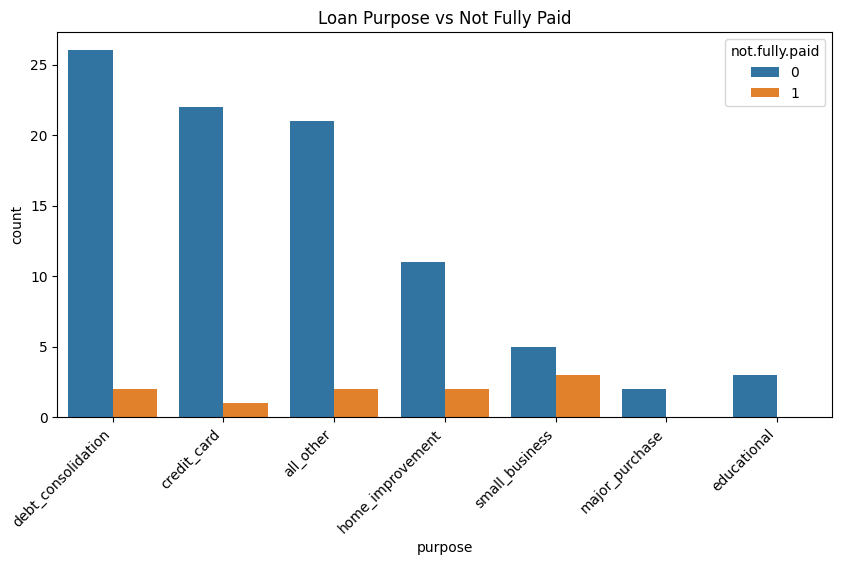

In [5]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load the Loan Data
df = pd.read_csv("https://raw.githubusercontent.com/tofighi/MachineLearning/refs/heads/master/datasets/loan_data.csv")
display(df.head())

# Dataset info
df.info()

# Countplot for purpose vs not.fully.paid
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x="purpose", hue="not.fully.paid")
plt.xticks(rotation=45, ha="right")
plt.title("Loan Purpose vs Not Fully Paid")
plt.show()

In [6]:
# Convert categorical column 'purpose' using get_dummies
pre_df = pd.get_dummies(df, columns=["purpose"], drop_first=True)

# Define features (X) and target (y)
X = pre_df.drop("not.fully.paid", axis=1)
y = pre_df["not.fully.paid"]

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.33, random_state=125
)

# Train Gaussian Naive Bayes model
model = GaussianNB()
model.fit(X_train, y_train)

GaussianNB()

Accuracy: 0.8484848484848485
F1 Score: 0.9180327868852459


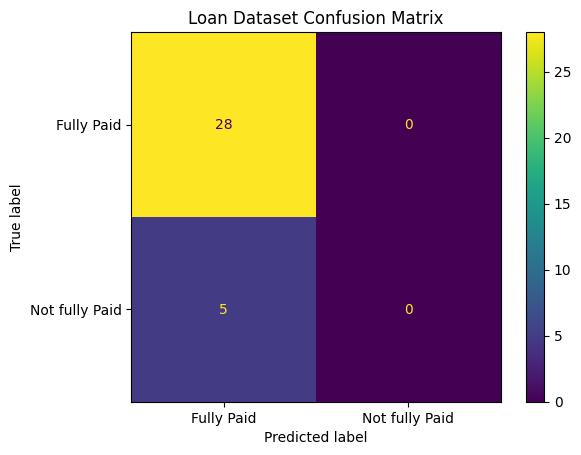

In [7]:
# Evaluate model
y_pred = model.predict(X_test)
accuracy = accuracy_score(y_pred, y_test)
f1 = f1_score(y_pred, y_test, average="weighted")

print("Accuracy:", accuracy)
print("F1 Score:", f1)

# Confusion Matrix for Loan Data
labels = ["Fully Paid", "Not fully Paid"]
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
disp.plot()
plt.title("Loan Dataset Confusion Matrix")
plt.show()